# 04 Train the load forecast

**Purpose.** Pick the model that forecasts each transformer's next 24 h of load, and tune it.

**Data.** `data/sim/` (dev scale, seed 7), training days only. Validation is the last week before the held-out week; the held-out week is used once, in `06`.

**Outcome.** Chosen model and parameters in `notebooks/results/04_load_forecast.json`, with the validation numbers behind the choice.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # optuna imports tqdm
import numpy as np
import optuna
import pandas as pd
import plotly.express as px
from _data import HOLIDAYS, holdout_start, load_tables
from _features import LOAD_FEATURES
from _models import SEED, fit_load_model, load_table, save_result
from _style import COLORS, label
from sklearn.linear_model import Ridge

optuna.logging.set_verbosity(optuna.logging.WARNING)
tables = load_tables()
load, transformers, weather = tables["load"], tables["transformers"], tables["weather"]
cutoff = holdout_start(load)
valid_start = cutoff - pd.Timedelta(days=7)
table = load_table(load[load["ts"] < cutoff], HOLIDAYS)
table = table[table["ts"] >= table["ts"].min() + pd.Timedelta(days=7)]
train = table[table["ts"] < valid_start]
valid = table[table["ts"] >= valid_start].dropna(subset=["transformer_kw"])
print(f"train {train['ts'].min():%Y-%m-%d} to {valid_start:%Y-%m-%d} ({len(train):,} rows), validate to {cutoff:%Y-%m-%d} ({len(valid):,} rows)")


def mae(pred: np.ndarray, frame: pd.DataFrame = valid) -> float:
    return float(np.abs(np.asarray(pred) - frame["transformer_kw"].to_numpy()).mean())

train 2026-04-08 to 2026-05-13 (171,360 rows), validate to 2026-05-20 (33,988 rows)


## Baselines
Seasonal naive is SILIP's baseline (docs/SPEC.md#models): the same interval last week. When last week's interval is missing, it falls back to the mean of that week, as `silip_ml` does.

In [2]:
week_mean = valid.groupby("transformer_id")["lag_7d"].transform("mean")
seasonal_naive = valid["lag_7d"].fillna(week_mean)
scores = [{"model": "seasonal naive (baseline)", "MAE (kW)": mae(seasonal_naive)}]
scores.append({"model": "yesterday (lag_1d)", "MAE (kW)": mae(valid["lag_1d"].fillna(seasonal_naive))})
pd.DataFrame(scores).round(3)

,model,MAE (kW)
0,seasonal naive (baseline),6.771
1,yesterday (lag_1d),5.801


## Candidates
A linear model (ridge regression on the lags plus one-hot hour and weekend flags) and LightGBM with default settings.

In [3]:
def linear_inputs(frame: pd.DataFrame) -> np.ndarray:
    week = frame["lag_7d"].fillna(frame["lag_1d"]).fillna(0.0)  # ridge needs no gaps: fill from the other lags
    lags = np.column_stack([frame[c].fillna(week).to_numpy() for c in ["lag_1d", "lag_2d", "lag_7d"]])
    hours = np.eye(24)[frame["hour"].astype(int)]
    return np.column_stack([lags, hours, frame[["is_weekend", "is_holiday"]].to_numpy()])


ridge = Ridge(alpha=1.0).fit(linear_inputs(train.dropna(subset=["transformer_kw"])), train["transformer_kw"].dropna())
scores.append({"model": "ridge (lags + hour)", "MAE (kW)": mae(ridge.predict(linear_inputs(valid)))})
DEFAULT = {"n_estimators": 200, "learning_rate": 0.05}
default_model = fit_load_model(train, DEFAULT)
scores.append({"model": "LightGBM, default", "MAE (kW)": mae(default_model.predict(valid[LOAD_FEATURES].to_numpy()))})
pd.DataFrame(scores).round(3)

,model,MAE (kW)
0,seasonal naive (baseline),6.771
1,yesterday (lag_1d),5.801
2,ridge (lags + hour),6.331
3,"LightGBM, default",3.848


Takeaway: both learned models beat the baseline; LightGBM beats ridge because the hour-by-weekend interactions are not linear.

## Tune LightGBM on the time split
Optuna (seeded TPE sampler, 20 trials) searches tree size, learning rate and regularisation. Each trial trains on the training weeks and scores on the validation week, never on the held-out week.

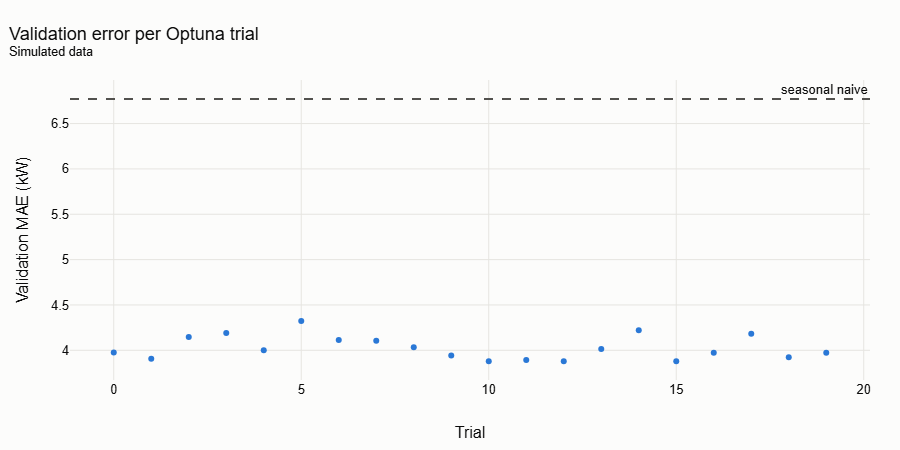

{'n_estimators': 200,
 'learning_rate': 0.029563376483344235,
 'num_leaves': 30,
 'min_child_samples': 174,
 'subsample': 0.717590096317249,
 'colsample_bytree': 0.6529880974473807,
 'reg_lambda': 0.0014636441693424017,
 'subsample_freq': 1}

In [4]:
def objective(trial: optuna.Trial) -> float:
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 300, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    return mae(fit_load_model(train, params).predict(valid[LOAD_FEATURES].to_numpy()))


study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=20)
best_params = {**study.best_params, "subsample_freq": 1}
trials = study.trials_dataframe()[["number", "value"]].rename(columns={"value": "MAE (kW)"})
fig = px.scatter(trials, x="number", y="MAE (kW)", color_discrete_sequence=COLORS[:1])
fig.add_hline(y=scores[0]["MAE (kW)"], line_dash="dash", line_color="#52514e", annotation_text="seasonal naive")
label(fig, "Validation error per Optuna trial", "Trial", "Validation MAE (kW)").show()
best_params

In [5]:
tuned_model = fit_load_model(train, best_params)
tuned_pred = tuned_model.predict(valid[LOAD_FEATURES].to_numpy())
scores.append({"model": "LightGBM, tuned", "MAE (kW)": mae(tuned_pred)})
results = pd.DataFrame(scores)
results["vs baseline"] = (results["MAE (kW)"] / results["MAE (kW)"].iloc[0] - 1).map("{:+.0%}".format)
results.round(3)

,model,MAE (kW),vs baseline
0,seasonal naive (baseline),6.771,+0%
1,yesterday (lag_1d),5.801,-14%
2,ridge (lags + hour),6.331,-6%
3,"LightGBM, default",3.848,-43%
4,"LightGBM, tuned",3.879,-43%


## Where is the error?
Compare the tuned model with the baseline by hour, rating and scenario.

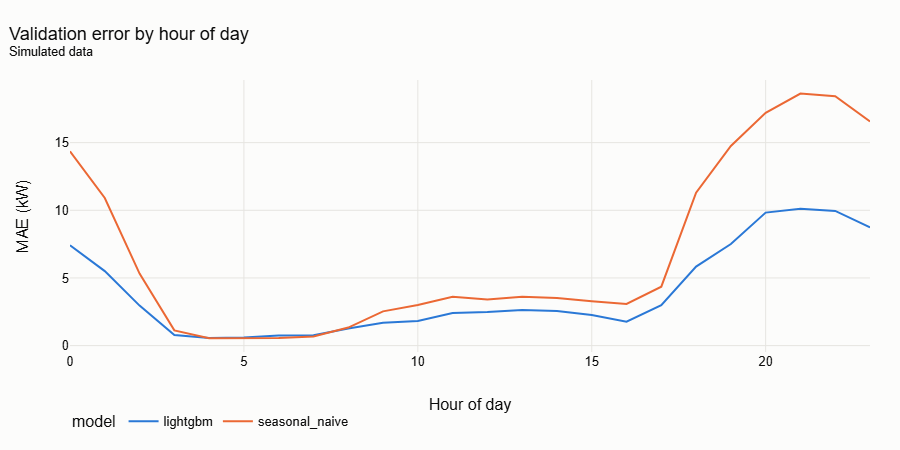

In [6]:
errors = valid[["transformer_id", "ts", "hour", "transformer_kw"]].assign(
    lightgbm=np.abs(tuned_pred - valid["transformer_kw"]), seasonal_naive=np.abs(seasonal_naive - valid["transformer_kw"])
).merge(transformers[["transformer_id", "rated_kva", "loading_class", "ev_site", "has_jumper", "lead_up"]], on="transformer_id")
errors = errors.merge(weather[["ts", "weather"]], on="ts")
by_hour = errors.groupby(errors["hour"].astype(int))[["lightgbm", "seasonal_naive"]].mean().reset_index().melt("hour", var_name="model", value_name="mae")
fig = px.line(by_hour, x="hour", y="mae", color="model", color_discrete_sequence=COLORS)
label(fig, "Validation error by hour of day", "Hour of day", "MAE (kW)").show()

Takeaway: most error sits in the evening peak, the hours that matter for risk; LightGBM cuts it most there.

In [7]:
def by(column: str) -> pd.DataFrame:
    return errors.groupby(column)[["lightgbm", "seasonal_naive"]].mean().round(2)


pd.concat({"rating (kVA)": by("rated_kva"), "loading class": by("loading_class"), "EV neighbourhood": by("ev_site"), "jumper": by("has_jumper"), "weather": by("weather")})

lightgbm  seasonal_naive
rating (kVA)     25.0           2.00            3.48
                 37.5           1.98            3.51
                 50.0           3.37            5.85
                 75.0           4.14            7.46
                 100.0          4.60            7.83
loading class    light          3.74            6.52
                 normal         3.78            6.58
                 over           3.99            7.09
                 tight          4.48            7.77
EV neighbourhood False          3.78            6.72
                 True           4.21            6.93
jumper           False          3.84            6.73
                 True           4.08            6.98
weather          clear          4.78            9.47
                 hot_spell      3.73            6.32

Takeaway: error grows with transformer size (it is in kW) and is largest on clear days right after a hot spell, when yesterday's heat no longer applies and no lag can see the change coming. LightGBM wins in every group.

## Choice
LightGBM with the tuned parameters: lowest validation error, beats the baseline in every hour, rating and scenario group, and runs as one batch call at inference. `06` retrains it on all training days and checks it once on the held-out week.

In [8]:
save_result("04_load_forecast", {
    "chosen": "lightgbm",
    "params": best_params,
    "features": LOAD_FEATURES,
    "validation_window": [str(valid_start), str(cutoff)],
    "validation_mae_kw": results.set_index("model")["MAE (kW)"].round(4).to_dict(),
})
results.round(3)

,model,MAE (kW),vs baseline
0,seasonal naive (baseline),6.771,+0%
1,yesterday (lag_1d),5.801,-14%
2,ridge (lags + hour),6.331,-6%
3,"LightGBM, default",3.848,-43%
4,"LightGBM, tuned",3.879,-43%


**Outcome.** Tuned LightGBM is chosen; its parameters are saved for `05` (which needs day-ahead forecasts to train on) and `06` (final training and export).

## Day-ahead weather: `lightgbm_weather`
The same procedure with the three weather inputs from `03` (forecasts issued by 00:00 of each day, never the true weather). Its own Optuna search, same seed, same validation week; compared with the tuned `lightgbm` above. Saved under a new name; `lightgbm` stays as it is.

In [9]:
from _features import LOAD_FEATURES_WEATHER, add_weather_features

wtable = add_weather_features(table, tables["weather_forecast"], transformers)
wtrain, wvalid = wtable[wtable["ts"] < valid_start], wtable[wtable["ts"] >= valid_start].dropna(subset=["transformer_kw"])
assert (wvalid[["transformer_id", "ts"]].to_numpy() == valid[["transformer_id", "ts"]].to_numpy()).all()


def weather_objective(trial: optuna.Trial) -> float:
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 300, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    return mae(fit_load_model(wtrain, params, LOAD_FEATURES_WEATHER).predict(wvalid[LOAD_FEATURES_WEATHER].to_numpy()))


wstudy = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
wstudy.optimize(weather_objective, n_trials=20)
weather_params = {**wstudy.best_params, "subsample_freq": 1}
weather_pred = fit_load_model(wtrain, weather_params, LOAD_FEATURES_WEATHER).predict(wvalid[LOAD_FEATURES_WEATHER].to_numpy())
scores.append({"model": "LightGBM + weather, tuned", "MAE (kW)": mae(weather_pred)})
results = pd.DataFrame(scores)
results["vs baseline"] = (results["MAE (kW)"] / results["MAE (kW)"].iloc[0] - 1).map("{:+.0%}".format)
results.round(3)

,model,MAE (kW),vs baseline
0,seasonal naive (baseline),6.771,+0%
1,yesterday (lag_1d),5.801,-14%
2,ridge (lags + hour),6.331,-6%
3,"LightGBM, default",3.848,-43%
4,"LightGBM, tuned",3.879,-43%
5,"LightGBM + weather, tuned",3.175,-53%


In [10]:
errors = errors.merge(wvalid[["transformer_id", "ts"]].assign(lightgbm_weather=np.abs(weather_pred - wvalid["transformer_kw"].to_numpy())), on=["transformer_id", "ts"])


def by_weather(column: str) -> pd.DataFrame:
    return errors.groupby(column)[["seasonal_naive", "lightgbm", "lightgbm_weather"]].mean().round(2)


pd.concat({"rating (kVA)": by_weather("rated_kva"), "weather": by_weather("weather")})

seasonal_naive  lightgbm  lightgbm_weather
rating (kVA) 25.0                 3.48      2.00              1.96
             37.5                 3.51      1.98              1.92
             50.0                 5.85      3.37              2.84
             75.0                 7.46      4.14              3.34
             100.0                7.83      4.60              3.66
weather      clear                9.47      4.78              3.78
             hot_spell            6.32      3.73              3.07

Takeaway: on the validation week `lightgbm_weather` (3.18 kW) beats the tuned `lightgbm` (3.88 kW), in every rating and weather group, in line with `03`. Both are exported by `06` and checked once on the held-out week.

In [11]:
save_result("04_load_forecast_weather", {
    "chosen": "lightgbm_weather",
    "params": weather_params,
    "features": LOAD_FEATURES_WEATHER,
    "validation_window": [str(valid_start), str(cutoff)],
    "validation_mae_kw": results.set_index("model")["MAE (kW)"].round(4).to_dict(),
})